In [8]:
import numpy as np
import pandas as pd


In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
file_path = "/content/drive/MyDrive/EconoCasual/data.csv"

df = pd.read_csv(file_path)

print(df.shape)
display(df.head())

(64000, 9)


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
0,10,142.44,1,0,Surburban,0,Phone,Buy One Get One,0
1,6,329.08,1,1,Rural,1,Web,No Offer,0
2,7,180.65,0,1,Surburban,1,Web,Buy One Get One,0
3,9,675.83,1,0,Rural,1,Web,Discount,0
4,2,45.34,1,0,Urban,0,Web,Buy One Get One,0


In [18]:

df = pd.read_csv("data.csv")

display(df.head())
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
0,10,142.44,1,0,Surburban,0,Phone,Buy One Get One,0
1,6,329.08,1,1,Rural,1,Web,No Offer,0
2,7,180.65,0,1,Surburban,1,Web,Buy One Get One,0
3,9,675.83,1,0,Rural,1,Web,Discount,0
4,2,45.34,1,0,Urban,0,Web,Buy One Get One,0


Shape: (64000, 9)

Columns:
['recency', 'history', 'used_discount', 'used_bogo', 'zip_code', 'is_referral', 'channel', 'offer', 'conversion']

Missing values:
recency          0
history          0
used_discount    0
used_bogo        0
zip_code         0
is_referral      0
channel          0
offer            0
conversion       0
dtype: int64


In [19]:
# Check data types and basic information
df.info()

# Statistical summary of numerical columns
display(df.describe())

# Check the target variable
print(df["conversion"].value_counts())
print(df["conversion"].value_counts(normalize=True) * 100)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   recency        64000 non-null  int64  
 1   history        64000 non-null  float64
 2   used_discount  64000 non-null  int64  
 3   used_bogo      64000 non-null  int64  
 4   zip_code       64000 non-null  object 
 5   is_referral    64000 non-null  int64  
 6   channel        64000 non-null  object 
 7   offer          64000 non-null  object 
 8   conversion     64000 non-null  int64  
dtypes: float64(1), int64(5), object(3)
memory usage: 4.4+ MB


,recency,history,used_discount,used_bogo,is_referral,conversion
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,5.763734,242.085656,0.551031,0.549719,0.502250,0.146781
std,3.507592,256.158608,0.497393,0.497526,0.499999,0.353890
min,1.000000,29.990000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,64.660000,0.000000,0.000000,0.000000,0.000000
50%,6.000000,158.110000,1.000000,1.000000,1.000000,0.000000
75%,9.000000,325.657500,1.000000,1.000000,1.000000,0.000000
max,12.000000,3345.930000,1.000000,1.000000,1.000000,1.000000


conversion
0    54606
1     9394
Name: count, dtype: int64
conversion
0    85.321875
1    14.678125
Name: proportion, dtype: float64


In [12]:
# Examine categorical columns
for col in ["channel", "offer", "zip_code"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())

# Conversion rate by offer
print("\nConversion rate by offer:")
display(
    df.groupby("offer")["conversion"]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
)

# Conversion rate by channel
print("\nConversion rate by channel:")
display(
    df.groupby("channel")["conversion"]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
)


--- channel ---
channel
Web             28217
Phone           28021
Multichannel     7762
Name: count, dtype: int64

--- offer ---
offer
Buy One Get One    21387
Discount           21307
No Offer           21306
Name: count, dtype: int64

--- zip_code ---
zip_code
Surburban    28776
Urban        25661
Rural         9563
Name: count, dtype: int64

Conversion rate by offer:


,count,mean
offer,,
Discount,21307,0.182757
Buy One Get One,21387,0.151400
No Offer,21306,0.106167



Conversion rate by channel:


,count,mean
channel,,
Multichannel,7762,0.171734
Web,28217,0.159407
Phone,28021,0.127155


In [13]:
# Conversion rate by previous discount usage
display(
    df.groupby("used_discount")["conversion"]
      .agg(["count", "mean"])
)

# Conversion rate by previous BOGO usage
display(
    df.groupby("used_bogo")["conversion"]
      .agg(["count", "mean"])
)

# Conversion rate by referral status
display(
    df.groupby("is_referral")["conversion"]
      .agg(["count", "mean"])
)

# Conversion rate by customer recency
display(
    df.groupby("recency")["conversion"]
      .mean()
      .sort_index()
)

,count,mean
used_discount,,
0,28734,0.144150
1,35266,0.148925


,count,mean
used_bogo,,
0,28818,0.126449
1,35182,0.163436


,count,mean
is_referral,,
0,31856,0.173060
1,32144,0.120738


,conversion
recency,
1,0.193029
2,0.177790
3,0.166328
4,0.148907
5,0.142350
6,0.140717
7,0.133889
8,0.127897
9,0.113957


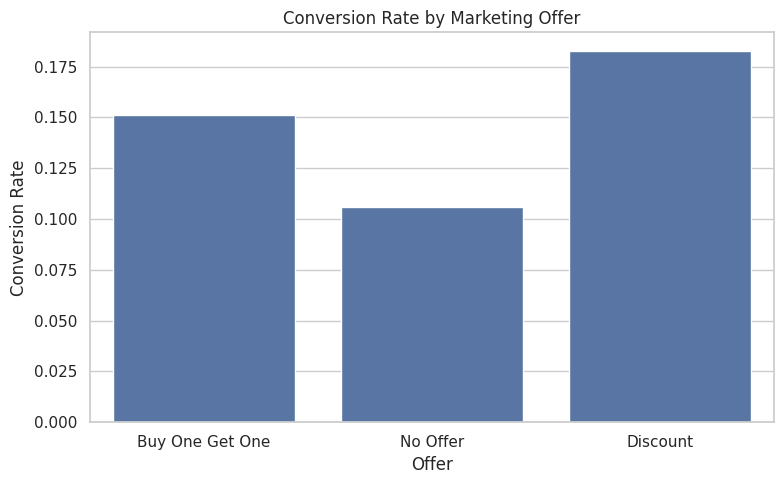

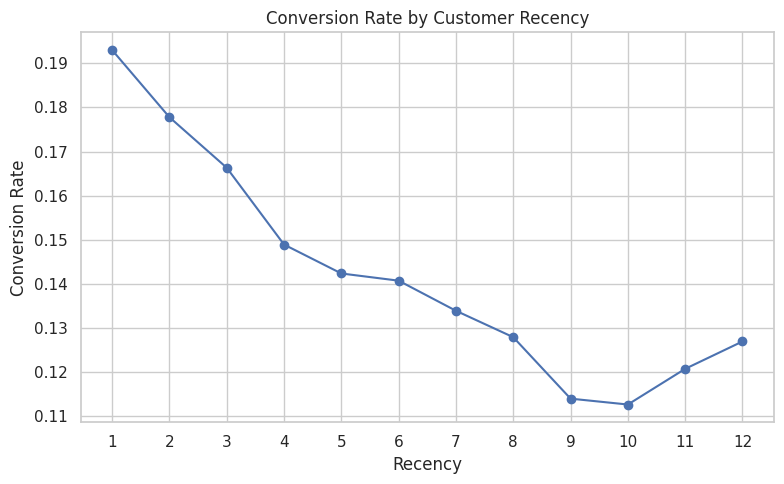

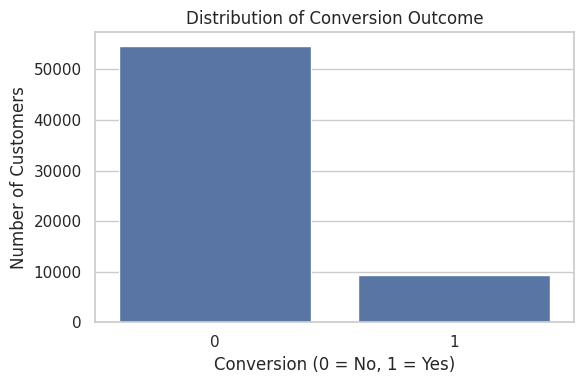

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Conversion rate by offer
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="offer", y="conversion",
            errorbar=None)
plt.title("Conversion Rate by Marketing Offer")
plt.ylabel("Conversion Rate")
plt.xlabel("Offer")
plt.tight_layout()
plt.show()

# 2. Conversion rate by customer recency
recency_rate = df.groupby("recency")["conversion"].mean()

plt.figure(figsize=(8, 5))
recency_rate.plot(marker="o")
plt.title("Conversion Rate by Customer Recency")
plt.xlabel("Recency")
plt.ylabel("Conversion Rate")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

# 3. Distribution of conversion outcome
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="conversion")
plt.title("Distribution of Conversion Outcome")
plt.xlabel("Conversion (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Key EDA Findings

1. The dataset contains 64,000 observations and 9 columns, with no missing values.
2. The overall customer conversion rate is approximately 14.68%.
3. The Discount offer has the highest observed conversion rate (18.28%), followed by Buy One Get One (15.14%) and No Offer (10.62%).
4. The Multichannel group has the highest observed conversion rate among the three channels, at approximately 17.17%.
5. Customers with previous BOGO usage have a higher observed conversion rate than customers without previous BOGO usage.
6. Conversion rates generally decline as recency increases, although the pattern is not perfectly monotonic.

Limitation: These findings describe associations in the observed data. They do not establish that a particular offer causes higher conversion. Further causal analysis is needed to account for potential confounding factors.